# ДЗ #2. Агрегация асессорских оценок

**Задание.** Сгенерировать или найти датасет асессорских оценок, посчитать по нему разные статистики и описать,
почему они похожи на реальные данные. Применить методы агрегации Majority Vote, Weighted Majority Vote и
Dawid-Skene, замерить качество, сделать выводы.

**Что сделано.**

1. Написан генератор краудсорсинговой разметки (`crowd/simulation.py`) с известной истинной разметкой:
   задача трёхклассовой разметки тональности (`negative / neutral / positive`).
2. Посчитаны статистики датасета и показано, какими свойствами реальных данных он обладает.
3. С нуля реализованы MV, два варианта WMV и Dawid-Skene (EM), а также Dawid-Skene с контрольными заданиями
   (`crowd/aggregation.py`, покрыто тестами в `tests/`).
4. Качество измерено на основной выборке, в разрезах по перекрытию и сложности, а также в двух сериях
   экспериментов: при росте доли спамеров и при разном фиксированном перекрытии.

Генерируемые данные не сохраняются на диск: всё воспроизводится из кода по зафиксированному `SEED`.

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
from crowd.aggregation import DawidSkene, correct_answer_counts
from crowd.experiments import (
    accuracy_by_group,
    aggregate_all,
    evaluation_tasks,
    mean_absolute_errors,
    quality_table,
    rank_correlations,
    run_sweep,
    summarize_sweep,
    worker_quality_estimates,
)
from crowd.plotting import plot_confusion_matrices, plot_sweep
from crowd.simulation import CLASS_NAMES, CrowdConfig, generate_crowd_dataset, with_spammer_share
from crowd.statistics import (
    gini_coefficient,
    krippendorff_alpha_nominal,
    label_confusion,
    labels_per_task,
    labels_per_worker,
    lorenz_curve,
    pairwise_agreement,
    top_workers_share,
)

In [3]:
SEED = 42
N_CLASSES = len(CLASS_NAMES)
MAIN_CONFIG = CrowdConfig(seed=SEED)

# Robustness experiments use smaller projects and several seeds to estimate the spread.
SWEEP_CONFIG = replace(MAIN_CONFIG, n_tasks=2000, n_workers=200)
SWEEP_SEEDS = range(5)
SPAMMER_SHARES = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
FIXED_OVERLAPS = [1, 2, 3, 5, 7, 9]

pd.set_option("display.precision", 3)
plt.rcParams["figure.dpi"] = 110

## 1. Генерация датасета

Моделируем проект по разметке тональности текстов на краудсорсинговой платформе. Генеративная модель:

| Компонент | Как моделируется | Зачем |
|---|---|---|
| Истинные классы | категориальное распределение с дисбалансом `(0.25, 0.30, 0.45)` | в реальных задачах классы почти всегда несбалансированы |
| Сложность задания $d_j$ | $\mathrm{Beta}(1.2, 4)$: большинство заданий простые, есть хвост сложных | неоднозначные тексты существуют всегда |
| Типы исполнителей | 70% добросовестных (точность $\sim\mathrm{Beta}(14, 2.5)$, в среднем ≈0.85), 15% невнимательных ($\mathrm{Beta}(5, 4)$, ≈0.56), 10% случайных кликеров, 5% «жмут одну кнопку» | типичный состав толпы |
| Ошибки исполнителя | своя матрица ошибок: ошибаются чаще в соседний класс (`negative`↔`neutral`), плюс личный перекос к некоторым классам (Дирихле) | ошибки в порядковых шкалах не равномерные |
| Влияние сложности | на задании сложности $d_j$ добросовестный исполнитель с вероятностью $d_j$ отвечает как «запутавшийся»: 50/50 между истинным и одним соседним классом, **одинаковым для всех** | ошибки на сложных заданиях коррелированы, их не исправит никакая агрегация |
| Активность | вес исполнителя $\sim\mathrm{LogNormal}(0, 1.2)$, задания раздаются пропорционально весу | небольшое ядро делает большую часть работы |
| Перекрытие | динамическое: 3 метки, затем добавляем по одной (до 5), пока доля самого частого ответа < 0.7 | так работает incremental relabeling на платформах |
| Контрольные задания | 5% заданий с известным ответом, простые, каждое видят 20 исполнителей | golden set — единственная доступная на практике «истина» |
| Время ответа | лог-нормальное, спамеры в 3–4 раза быстрее, на сложных заданиях честные исполнители медленнее | время — частый признак для фильтрации спамеров |

In [4]:
dataset = generate_crowd_dataset(MAIN_CONFIG)
labels = dataset.labels

print(f"labels: {labels.shape}, tasks: {dataset.tasks.shape}, workers: {dataset.workers.shape}")
labels.head()

labels: (19297, 4), tasks: (4000, 4), workers: (300, 4)


,task,worker,label,answer_time
0,0,106,2,18.959
1,0,225,2,35.733
2,0,117,2,27.397
3,1,11,1,16.803
4,1,56,0,2.126


## 2. Статистики датасета

Ниже — только те статистики, которые можно посчитать на реальном проекте без знания истинных классов
(кроме отдельно помеченных: распределение типов исполнителей и матрица ошибок относительно истинной разметки).

### 2.1. Общий обзор и перекрытие

In [5]:
n_labels_per_task = labels_per_task(labels)
n_labels_per_worker = labels_per_worker(labels)
is_golden_task = dataset.tasks.set_index("task")["is_golden"]

overview = pd.Series({
    "tasks": dataset.tasks.shape[0],
    "golden tasks": int(is_golden_task.sum()),
    "workers with at least one label": n_labels_per_worker.shape[0],
    "labels": labels.shape[0],
    "mean labels per regular task": n_labels_per_task[~is_golden_task].mean(),
    "median labels per worker": n_labels_per_worker.median(),
    "max labels per worker": n_labels_per_worker.max(),
})
overview.to_frame("value")

,value
tasks,4000.000
golden tasks,200.000
workers with at least one label,300.000
labels,19297.000
mean labels per regular task,4.026
median labels per worker,30.500
max labels per worker,1237.000


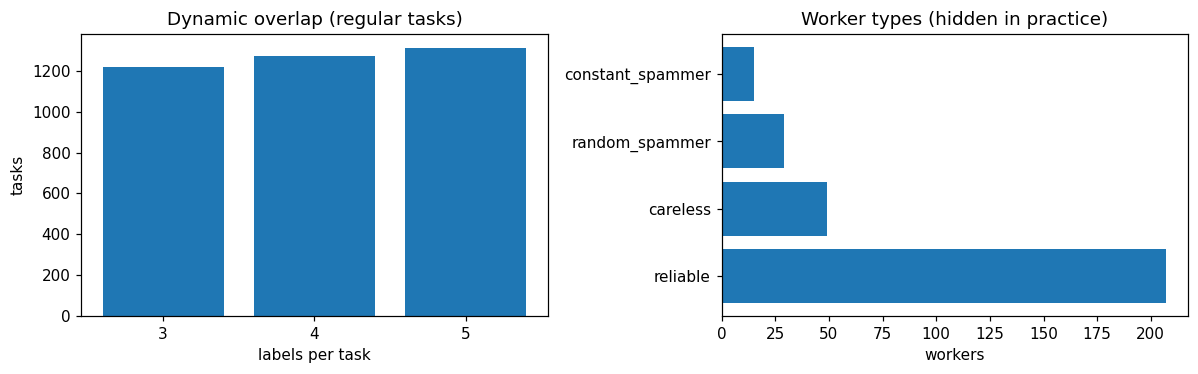

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))

overlap_counts = n_labels_per_task[~is_golden_task].value_counts().sort_index()
axes[0].bar(overlap_counts.index.astype(str), overlap_counts.to_numpy())
axes[0].set_xlabel("labels per task")
axes[0].set_ylabel("tasks")
axes[0].set_title("Dynamic overlap (regular tasks)")

worker_types = dataset.workers["type"].value_counts()
axes[1].barh(worker_types.index, worker_types.to_numpy())
axes[1].set_xlabel("workers")
axes[1].set_title("Worker types (hidden in practice)")

figure.tight_layout()
plt.show()

### 2.2. Активность исполнителей

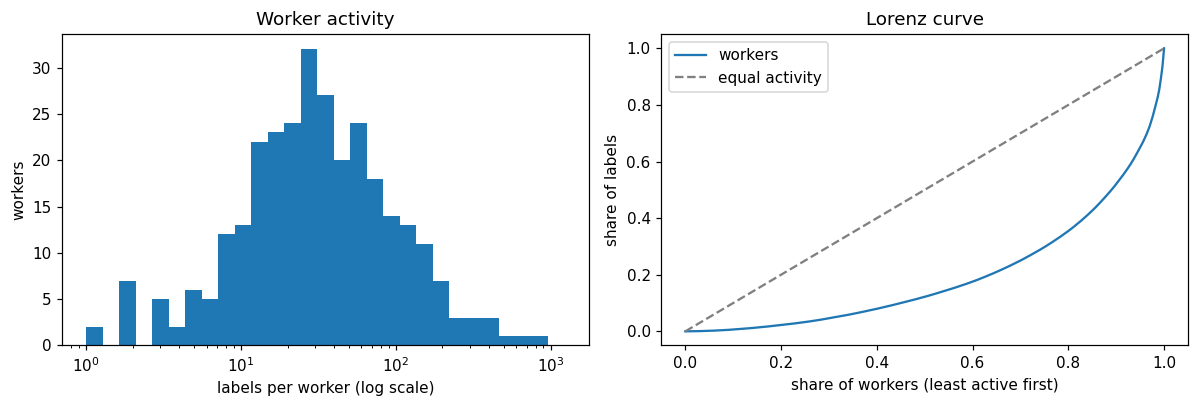

,value
Gini coefficient,0.605
share of labels by top 10% workers,0.480
share of labels by top 20% workers,0.645


In [7]:
lorenz_x, lorenz_y = lorenz_curve(n_labels_per_worker)
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(n_labels_per_worker, bins=np.logspace(0, np.log10(n_labels_per_worker.max()), 30))
axes[0].set_xscale("log")
axes[0].set_xlabel("labels per worker (log scale)")
axes[0].set_ylabel("workers")
axes[0].set_title("Worker activity")

axes[1].plot(lorenz_x, lorenz_y, label="workers")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="equal activity")
axes[1].set_xlabel("share of workers (least active first)")
axes[1].set_ylabel("share of labels")
axes[1].set_title("Lorenz curve")
axes[1].legend()

figure.tight_layout()
plt.show()

activity_stats = pd.Series({
    "Gini coefficient": gini_coefficient(n_labels_per_worker),
    "share of labels by top 10% workers": top_workers_share(n_labels_per_worker, 0.1),
    "share of labels by top 20% workers": top_workers_share(n_labels_per_worker, 0.2),
})
activity_stats.to_frame("value")

### 2.3. Распределение классов и согласованность исполнителей

Krippendorff's $\alpha$ (номинальная шкала) поддерживает разное число меток на задание: $\alpha = 1$ — полное
согласие, $\alpha = 0$ — согласие на уровне случайного. Считаем его по обычным заданиям.

In [8]:
regular_labels = labels[labels["task"].isin(is_golden_task.index[~is_golden_task])]
regular_tasks = dataset.tasks[~dataset.tasks["is_golden"]]

class_distribution = pd.DataFrame({
    "true labels (hidden)": regular_tasks["true_label"].value_counts(normalize=True),
    "raw worker labels": regular_labels["label"].value_counts(normalize=True),
}).sort_index()
class_distribution.index = list(CLASS_NAMES)
class_distribution

,true labels (hidden),raw worker labels
negative,0.258,0.284
neutral,0.295,0.359
positive,0.447,0.357


In [9]:
agreement = pairwise_agreement(regular_labels, N_CLASSES)
difficulty = dataset.tasks.set_index("task")["difficulty"]
difficulty_bins = pd.cut(difficulty, bins=[0.0, 0.1, 0.2, 0.4, 1.0])

agreement_stats = pd.Series({
    "Krippendorff alpha (nominal)": krippendorff_alpha_nominal(regular_labels, N_CLASSES),
    "mean pairwise agreement": agreement.mean(),
    "tasks with unanimous answers": (agreement == 1.0).mean(),
})
display(agreement_stats.to_frame("value"))

agreement_by_difficulty = agreement.groupby(difficulty_bins.reindex(agreement.index), observed=True).mean()
agreement_by_difficulty.to_frame("mean pairwise agreement").rename_axis("task difficulty")

,value
Krippendorff alpha (nominal),0.305
mean pairwise agreement,0.595
tasks with unanimous answers,0.320


,mean pairwise agreement
task difficulty,
"(0.0, 0.1]",0.623
"(0.1, 0.2]",0.623
"(0.2, 0.4]",0.581
"(0.4, 1.0]",0.546


### 2.4. Качество исполнителей, время ответа и матрица ошибок

Точность исполнителя оцениваем по контрольным заданиям — так это делается на практике. Цвет точки — скрытый тип
исполнителя, на практике он неизвестен.

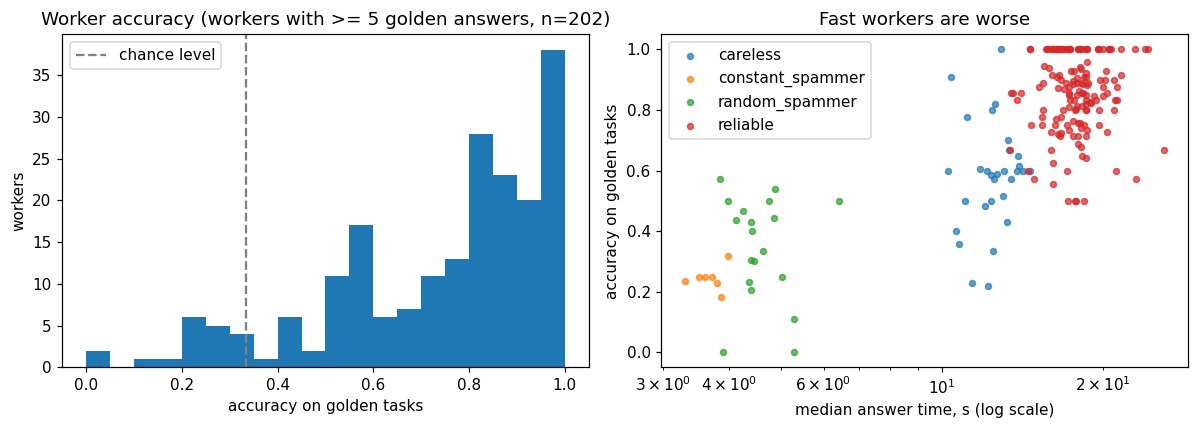

Spearman correlation between median answer time and golden accuracy: 0.574


In [10]:
golden_counts = correct_answer_counts(labels, dataset.golden_answers)
worker_summary = pd.DataFrame({
    "golden_accuracy": golden_counts["correct"] / golden_counts["total"],
    "n_golden": golden_counts["total"],
    "median_time": labels.groupby("worker")["answer_time"].median(),
    "type": dataset.workers.set_index("worker")["type"],
})
worker_summary = worker_summary[worker_summary["n_golden"] >= 5]

figure, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(worker_summary["golden_accuracy"], bins=20)
axes[0].axvline(1 / N_CLASSES, color="grey", linestyle="--", label="chance level")
axes[0].set_xlabel("accuracy on golden tasks")
axes[0].set_ylabel("workers")
axes[0].set_title(f"Worker accuracy (workers with >= 5 golden answers, n={len(worker_summary)})")
axes[0].legend()

for worker_type, group in worker_summary.groupby("type"):
    axes[1].scatter(group["median_time"], group["golden_accuracy"], s=15, alpha=0.7, label=worker_type)
axes[1].set_xscale("log")
axes[1].set_xlabel("median answer time, s (log scale)")
axes[1].set_ylabel("accuracy on golden tasks")
axes[1].set_title("Fast workers are worse")
axes[1].legend()

figure.tight_layout()
plt.show()

print(
    "Spearman correlation between median answer time and golden accuracy: "
    f"{worker_summary['median_time'].corr(worker_summary['golden_accuracy'], method='spearman'):.3f}"
)

In [11]:
raw_confusion = label_confusion(regular_labels, dataset.tasks, N_CLASSES)
raw_confusion.index = [f"true {name}" for name in CLASS_NAMES]
raw_confusion.columns = [f"answer {name}" for name in CLASS_NAMES]
raw_confusion

,answer negative,answer neutral,answer positive
true negative,0.708,0.220,0.072
true neutral,0.191,0.666,0.143
true positive,0.110,0.234,0.656


### 2.5. Почему эти данные похожи на реальные

* **Тяжёлый хвост активности.** Распределение числа меток на исполнителя близко к лог-нормальному, Gini ≈ 0.6,
  10% самых активных исполнителей делают почти половину разметки, а медианный исполнитель — около 30 меток. Такая картина («немногие делают большую часть работы»)
  стабильно наблюдается в исследованиях Amazon Mechanical Turk и на открытых датасетах Toloka;
  много исполнителей сделали лишь несколько заданий.
* **Умеренная согласованность.** $\alpha$ Криппендорфа ≈ 0.3 и средняя попарная согласованность ≈ 0.6 — типичный
  уровень для субъективных задач вроде тональности, где у краудсорсинга $\alpha$ обычно 0.2–0.6, а не близко к 1.
  Согласованность монотонно падает с ростом сложности задания.
* **Неравномерные ошибки.** Матрица ошибок отдельных меток диагонально доминирующая, но не диагональная, и
  несимметричная: `neutral` путают с обоими соседями, а `negative` ↔ `positive` путают редко. Это свойство
  порядковых шкал.
* **Смещение распределения меток.** Сырые метки «размазаны» к нейтральному и к минорным классам относительно
  истинного распределения — из-за спамеров и ошибок в соседний класс.
* **Разнородная толпа.** На контрольных заданиях видна бимодальность: основная масса с точностью 0.8–0.95 и
  отдельная группа около уровня случайного угадывания. Быстрые исполнители в среднем хуже — на реальных
  платформах это используется для фильтрации («слишком быстрые ответы»).
* **Динамическое перекрытие.** Большинство заданий получило 3–5 меток: на спорные задания платформа
  докупает разметку.

## 3. Методы агрегации

Обозначения: $y_{ij}$ — ответ исполнителя $i$ на задание $j$, $K = 3$ — число классов.

**Majority Vote (MV).** $\hat z_j = \arg\max_k \sum_i [y_{ij} = k]$. Ничьи разрешаются случайно (выбор первого
класса систематически сместил бы результат к нему).

**Weighted Majority Vote (WMV).** $\hat z_j = \arg\max_k \sum_i w_i [y_{ij} = k]$. Вес — логарифм отношения шансов
$w_i = \log\frac{(K - 1)\,p_i}{1 - p_i}$: это байесовски оптимальный вес, если исполнитель с точностью $p_i$ ошибается
равномерно. Исполнители на уровне случайного ($p_i \le 1/K$) получают вес 0. Точность $p_i$ оцениваем двумя способами:

* **WMV (golden)** — по контрольным заданиям со сглаживанием к среднему: $p_i = \frac{c_i + m\,\bar p}{n_i + m}$, $m = 5$;
* **WMV (agreement)** — без ground truth: итеративно, как согласие исполнителя с текущим агрегатом (старт с MV).

**Dawid-Skene (DS).** Каждому исполнителю — полная матрица ошибок $\pi^{(i)}_{kl} = P(y_{ij} = l \mid z_j = k)$,
ответы независимы при известном истинном классе. EM-алгоритм:

* E-шаг: $P(z_j = k \mid y) \propto \rho_k \prod_i \pi^{(i)}_{k\,y_{ij}}$ (в лог-пространстве);
* M-шаг: $\rho_k$ и $\pi^{(i)}$ — взвешенные апостериорными вероятностями частоты (со сглаживанием Лапласа).

Инициализация — нормированные голоса MV. **DS (golden)** — тот же EM, но апостериорные вероятности контрольных
заданий зафиксированы на известном ответе.

Качество меряем по обычным заданиям: контрольные исключены, так как часть методов использует их ответы.

## 4. Качество агрегации на основном датасете

In [12]:
predictions = aggregate_all(dataset, seed=SEED)
true_labels = evaluation_tasks(dataset)

quality = quality_table(predictions, true_labels)
quality["errors"] = ((1 - quality["accuracy"]) * len(true_labels)).round().astype(int)
quality

,accuracy,macro_f1,errors
MV,0.842,0.839,602
WMV (agreement),0.878,0.876,462
WMV (golden),0.877,0.875,468
Dawid-Skene,0.874,0.868,480
Dawid-Skene (golden),0.874,0.868,480


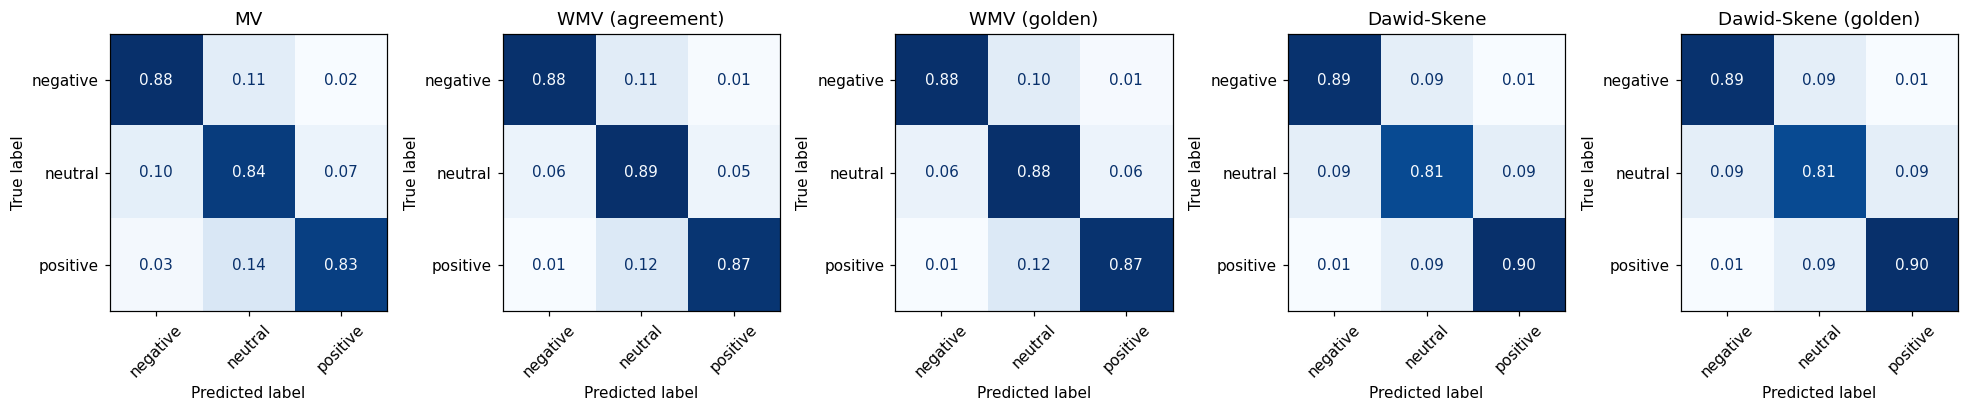

In [13]:
plot_confusion_matrices(predictions, true_labels, CLASS_NAMES)
plt.show()

### 4.1. Разрезы по перекрытию и сложности

In [14]:
overlap_groups = n_labels_per_task.rename("labels per task")
accuracy_by_group(predictions, true_labels, overlap_groups)

,n_tasks,MV,WMV (agreement),WMV (golden),Dawid-Skene,Dawid-Skene (golden)
labels per task,,,,,,
3,1216,0.957,0.957,0.957,0.954,0.954
4,1271,0.889,0.889,0.891,0.880,0.880
5,1313,0.688,0.795,0.788,0.793,0.793


In [15]:
accuracy_by_group(predictions, true_labels, difficulty_bins.rename("task difficulty"))

,n_tasks,MV,WMV (agreement),WMV (golden),Dawid-Skene,Dawid-Skene (golden)
task difficulty,,,,,,
"(0.0, 0.1]",940,0.899,0.934,0.936,0.927,0.927
"(0.1, 0.2]",949,0.883,0.922,0.919,0.914,0.914
"(0.2, 0.4]",1226,0.823,0.874,0.866,0.861,0.861
"(0.4, 1.0]",685,0.739,0.749,0.756,0.769,0.769


### 4.2. Сходимость Dawid-Skene и оценка качества исполнителей

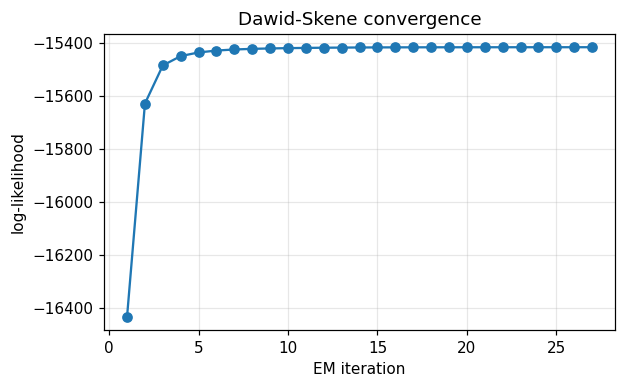

,estimated by Dawid-Skene,true
class prior,,
negative,0.264,0.25
neutral,0.296,0.30
positive,0.440,0.45


In [16]:
dawid_skene_result = DawidSkene(N_CLASSES).fit(labels)

figure, ax = plt.subplots(figsize=(6, 3.5))
log_likelihoods = dawid_skene_result.log_likelihoods
ax.plot(np.arange(1, len(log_likelihoods) + 1), log_likelihoods, marker="o")
ax.set_xlabel("EM iteration")
ax.set_ylabel("log-likelihood")
ax.set_title("Dawid-Skene convergence")
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame(
    {"estimated by Dawid-Skene": dawid_skene_result.class_prior, "true": MAIN_CONFIG.class_prior},
    index=list(CLASS_NAMES),
).rename_axis("class prior")

In [17]:
estimate_columns = ["golden", "agreement", "dawid_skene"]
worker_estimates = worker_quality_estimates(dataset)

pd.DataFrame({
    "Spearman with true accuracy": rank_correlations(worker_estimates, estimate_columns),
    "mean absolute error": mean_absolute_errors(worker_estimates, estimate_columns),
})

,Spearman with true accuracy,mean absolute error
golden,0.710,0.107
agreement,0.761,0.089
dawid_skene,0.722,0.102


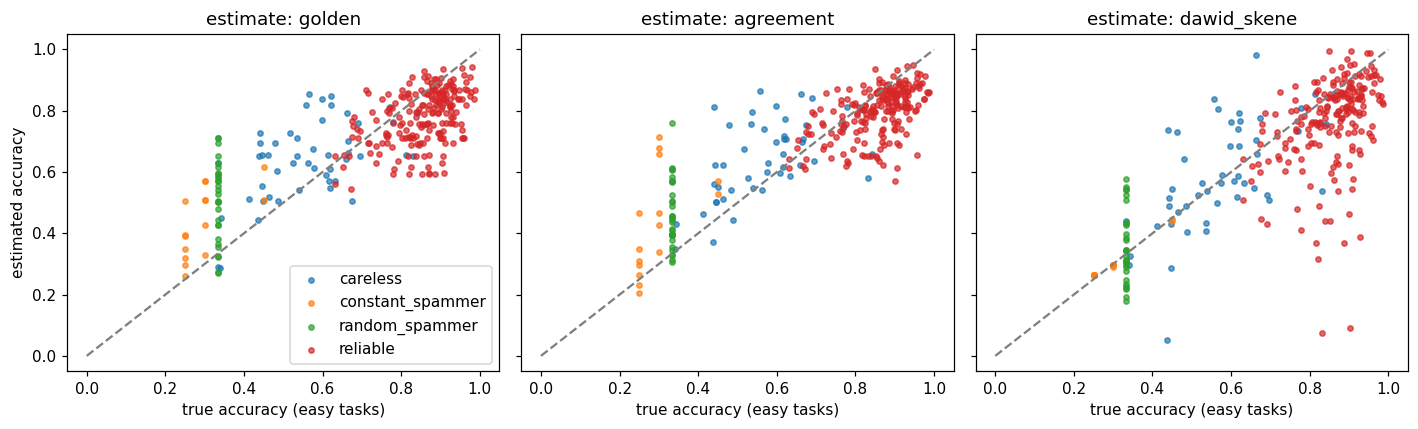

In [18]:
figure, axes = plt.subplots(1, len(estimate_columns), figsize=(13, 4), sharey=True)
for ax, column in zip(axes, estimate_columns, strict=True):
    for worker_type, group in worker_estimates.groupby("type"):
        ax.scatter(group["true_accuracy"], group[column], s=12, alpha=0.7, label=worker_type)
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey")
    ax.set_xlabel("true accuracy (easy tasks)")
    ax.set_title(f"estimate: {column}")
axes[0].set_ylabel("estimated accuracy")
axes[0].legend()
figure.tight_layout()
plt.show()

## 5. Устойчивость методов

Повторяем генерацию с разными сидами (среднее ± std по 5 запускам) и меняем один параметр:

* **долю спамеров** (случайных и «одна кнопка» в пропорции 2:1);
* **фиксированное перекрытие** — динамическое перекрытие отключено, каждое задание получает ровно $n$ меток.

In [19]:
spammer_sweep = run_sweep(SWEEP_CONFIG, SPAMMER_SHARES, with_spammer_share, SWEEP_SEEDS)
spammer_summary = summarize_sweep(spammer_sweep)
spammer_summary["mean"]

method,MV,WMV (agreement),WMV (golden),Dawid-Skene,Dawid-Skene (golden)
value,,,,,
0.0,0.896,0.907,0.906,0.905,0.905
0.1,0.858,0.885,0.883,0.880,0.880
0.2,0.817,0.859,0.860,0.860,0.860
0.3,0.782,0.847,0.844,0.841,0.841
0.4,0.741,0.830,0.823,0.822,0.820
0.5,0.685,0.791,0.792,0.785,0.784
0.6,0.600,0.720,0.734,0.719,0.723


In [20]:
def with_fixed_overlap(config: CrowdConfig, overlap: float) -> CrowdConfig:
    return replace(config, base_overlap=int(overlap), max_overlap=int(overlap))


overlap_sweep = run_sweep(SWEEP_CONFIG, FIXED_OVERLAPS, with_fixed_overlap, SWEEP_SEEDS)
overlap_summary = summarize_sweep(overlap_sweep)
overlap_summary["mean"]

method,MV,WMV (agreement),WMV (golden),Dawid-Skene,Dawid-Skene (golden)
value,,,,,
1,0.654,0.654,0.655,0.645,0.647
2,0.646,0.740,0.742,0.727,0.727
3,0.748,0.794,0.794,0.788,0.787
5,0.822,0.870,0.864,0.873,0.872
7,0.872,0.908,0.905,0.914,0.914
9,0.904,0.936,0.931,0.939,0.939


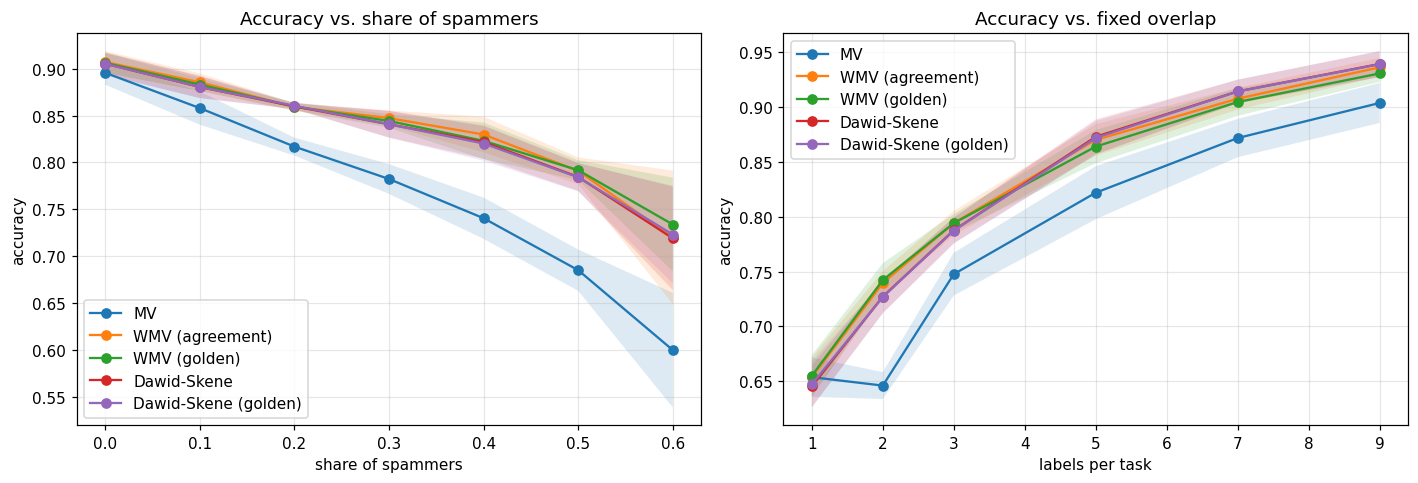

In [21]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
plot_sweep(spammer_summary, "share of spammers", "Accuracy vs. share of spammers", axes[0])
plot_sweep(overlap_summary, "labels per task", "Accuracy vs. fixed overlap", axes[1])
figure.tight_layout()
plt.show()

## 6. Выводы

1. **Простое голосование заметно уступает всем методам, учитывающим качество исполнителей.** На основном датасете
   MV даёт accuracy ≈ 0.84, а WMV и Dawid-Skene — ≈ 0.875–0.88, то есть исправляют около четверти ошибок MV.
   Весь выигрыш сосредоточен на спорных заданиях, получивших 5 меток: на них MV ≈ 0.69, взвешенные методы ≈ 0.79.
   На заданиях с единогласными тремя метками все методы совпадают.
2. **Разрыв растёт с долей спамеров.** Без спамеров методы почти равны (0.90 против 0.91), при 40% спамеров MV
   теряет ≈ 0.16 accuracy, а WMV / DS — ≈ 0.08. Спамеров «одна кнопка» Dawid-Skene распознаёт по матрице ошибок
   без всякой разметки, а WMV — по низкой точности на контроле или низкому согласию с агрегатом.
3. **Перекрытие важнее выбора метода, но метод экономит бюджет.** При перекрытии 1 агрегировать нечего, и все
   методы равны. При перекрытии 2 MV не лучше одной метки (каждая ничья решается монеткой), а взвешенные методы
   используют разницу в надёжности исполнителей. WMV/DS с 5 метками на задание точнее, чем MV с 7.
4. **Dawid-Skene не обогнал WMV на этих данных** — и это объяснимо:
   * у медианного исполнителя около 30 меток, а DS оценивает на каждого 6 свободных параметров матрицы ошибок;
     для малоактивных исполнителей оценки шумные;
   * основная часть оставшихся ошибок — коррелированные ошибки на сложных заданиях (вплоть до ≈ 0.75 accuracy в
     самой сложной корзине для всех методов). Модель DS предполагает независимость ответов при известном классе
     и не моделирует сложность заданий, поэтому такие ошибки исправить не может;
   * DS выигрывает при большом перекрытии (7–9 меток), когда матрицы ошибок оцениваются точнее, и лучше всех
     восстанавливает априорное распределение классов. При этом он склонен «перетягивать» спорные задания из
     `neutral` в более частый `positive`, из-за чего macro F1 у него чуть ниже, чем у WMV.
5. **Контрольные задания почти не добавили качества.** WMV (golden) и WMV (agreement) дают одинаковую точность,
   а фиксация golden-заданий в DS почти ничего не меняет: при 4000 заданиях и ~4 метках на задание данных для
   оценки качества исполнителей без учителя достаточно. Golden-задания остаются полезными для мониторинга и
   бана спамеров в процессе разметки, а также в «холодном старте», когда меток мало.
6. **Практическая рекомендация.** Начинать с WMV (дёшево, устойчиво, интерпретируемо) и использовать Dawid-Skene
   при большом перекрытии или когда нужны матрицы ошибок исполнителей. Если в задаче важны сложные задания,
   стоит смотреть в сторону моделей, учитывающих сложность (GLAD, MACE), и увеличивать перекрытие на спорных
   заданиях, как делает динамическое перекрытие.